# 모델·방법 비교 버블차트

현재까지 실행된 모델과 학습 방법을 같은 지표끼리 분리해 비교한다. 이 노트북은 프로젝트 CCTV identity 정확도를 주장하지 않으며, Qwen3.5-9B와 Qwen2.5-VL-7B-Instruct는 아직 미측정 후보로 표에만 표시한다.

## tl;dr

동일 CCTV proxy 45개 샘플에서 CLIP ViT-L/14가 속성 정확도 41.40%로 가장 높고, BLIP base가 p95 0.492초로 가장 빠르다. Qwen3-VL-2B는 39.30%지만 p95 8.164초이며, 현재 유효하게 실행된 5개 모델 모두 track exact가 0%다. PA-100K 계열의 SOLIDER·CrossPAR 수치는 별도 계약이므로 CCTV identity 결과와 합치지 않는다. Florence 두 실행은 현재 런타임 초기화 오류로 차트에서 제외했다.

## 실험 맥락과 방법

### 핵심 가정

- 첫 번째 차트: x=attribute accuracy, y=p95 latency이며 y는 낮을수록 좋다. 버블 크기는 대략적인 파라미터 수다.
- 두 번째 차트: x=PA-100K mA, y=InsF1이며 버블 크기는 학습 행 수의 로그 스케일이다.
- proxy, PA-100K subset, public reported 값은 서로 다른 평가 계약이므로 한 축으로 합치지 않는다.
- proxy는 10개 필드 스키마를 사용하지만 실제 라벨은 Simuletic 샘플당 9개, PA-100K 샘플당 5개다. 빈/unknown 필드는 분모에서 제외한다.
- p95는 모든 모델에 동일한 lower-index 정의를 적용한다: sorted(latencies)[max(0, int(n * 0.95) - 1)].
- 실제 승격에는 case/camera/track/identity-group-held-out CCTV 평가가 필요하다.

In [1]:
from pathlib import Path
import csv
import json
import math
import matplotlib.pyplot as plt
from matplotlib import font_manager
font_path = Path('C:/Windows/Fonts/NotoSansKR-Regular.ttf')
if font_path.exists():
    font_manager.fontManager.addfont(str(font_path))
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=str(font_path)).get_name()
plt.rcParams['axes.unicode_minus'] = False

project_root = Path.cwd()
if (project_root / 'results' / 'model_comparison_bubble_data.json').exists():
    project_root = project_root.parent
data_path = project_root / 'experiments' / 'results' / 'model_comparison_bubble_data.json'
data = json.loads(data_path.read_text(encoding='utf-8'))
assert data['schemaVersion'] == 'model-comparison-bubble-v1'
qwen_result_paths = sorted((project_root / 'experiments' / 'results').glob('qwen*_fair_*.json'))
qwen_measured = []
for result_path in qwen_result_paths:
    result = json.loads(result_path.read_text(encoding='utf-8'))
    if result.get('status') != 'valid':
        continue
    model = str(result.get('model', result_path.stem))
    qwen_measured.append({
        'label': f"{model} {result.get('method', 'unknown')}",
        'x': float(result['fieldAccuracyPct']),
        'y': float(result['exactMatchPct']),
        'bubble': 9.0 if '3.5' in model else 7.0,
        'status': 'measured',
        'metric': 'six-field proxy: field accuracy / exact match',
        'source': str(result_path),
    })
print(f"loaded={data_path} proxy_rows={len(data['proxyRuntime'])} pa_rows={len(data['pa100kAttribute'])} qwen_valid_rows={len(qwen_measured)}")

loaded=C:\Users\SSAFY\Desktop\2학기\qwen3vl-backend\experiments\results\model_comparison_bubble_data.json proxy_rows=5 pa_rows=3 qwen_valid_rows=0


## 데이터

원본 JSON 결과 파일을 좌표 계약으로 정규화했다. `status=measured`와 `status=reported_public`을 분리해 공개 수치를 local experiment처럼 보이지 않게 한다.

In [2]:
print('동일 CCTV proxy 속성·지연시간 좌표')
for row in data['proxyRuntime']:
    print(f"{row['label']}: x={row['x']:.2f}%, y={row['y']:.3f}s, bubble={row['bubble']}B, {row['status']}")
print('PA-100K 보조 좌표')
for row in data['pa100kAttribute']:
    print(f"{row['label']}: x={row['x']:.2f}%, y={row['y']:.2f}%, bubble={row['bubble']} rows, {row['status']}")
print('서버 후보 (동일 조건 측정 전이므로 메인 차트 제외):')
for row in data['serverCandidates']:
    print(f"{row['label']}: {row['status']}")

동일 CCTV proxy 속성·지연시간 좌표
Qwen3-VL-2B: x=39.30%, y=8.298s, bubble=2.0B, measured
CLIP ViT-B/32: x=38.60%, y=0.723s, bubble=0.151B, measured
CLIP ViT-L/14: x=41.40%, y=4.141s, bubble=0.427B, measured
SigLIP base: x=24.21%, y=0.778s, bubble=0.203B, measured
BLIP base: x=20.35%, y=0.468s, bubble=0.385B, measured
PA-100K 보조 좌표
SOLIDER Swin-B frozen head: x=66.95%, y=79.05%, bubble=10000 rows, measured
SOLIDER Swin-B fine-tune: x=69.58%, y=82.30%, bubble=2000 rows, measured
CrossPAR reported: x=86.90%, y=90.60%, bubble=80000 rows, reported_public
서버 후보 (동일 조건 측정 전이므로 메인 차트 제외):
Qwen3.5-9B: not_measured_on_project_cctv
Qwen2.5-VL-7B-Instruct: fallback_not_measured_on_project_cctv


## 결과

### 1. 동일 CCTV proxy 모델 비교 차트

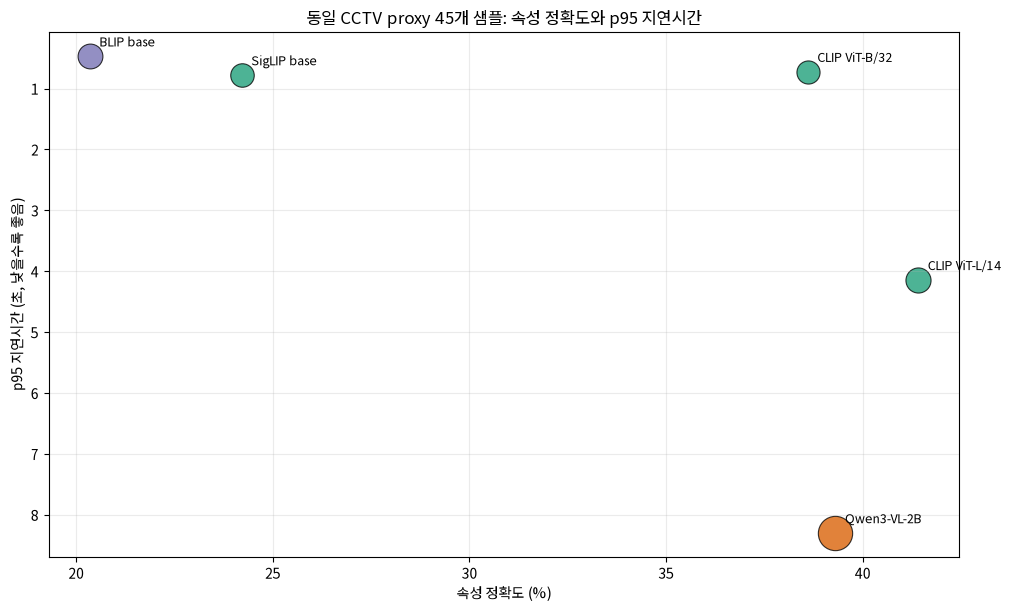

In [3]:
proxy_rows = [row for row in data['proxyRuntime'] if row['status'] == 'measured' and row['dataset'] == 'CCTV person-crop proxy']
colors = {'direct VLM structured JSON': '#d95f02', 'zero-shot field scoring': '#1b9e77', 'caption plus attribute parsing': '#7570b3', 'fine-tuned caption plus attribute parsing': '#e7298a'}
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
for row in proxy_rows:
    ax.scatter(row['x'], row['y'], s=250 + 180 * row['bubble'], alpha=0.78, color=colors[row['method']], edgecolor='black', linewidth=0.8)
    ax.annotate(row['label'], (row['x'], row['y']), xytext=(7, 7), textcoords='offset points', fontsize=9)
ax.invert_yaxis()
ax.set_title('동일 CCTV proxy 45개 샘플: 속성 정확도와 p95 지연시간')
ax.set_xlabel('속성 정확도 (%)')
ax.set_ylabel('p95 지연시간 (초, 낮을수록 좋음)')
ax.grid(alpha=0.25)
proxy_png = project_root / 'experiments' / 'results' / 'model_comparison_proxy_runtime_bubble.png'
proxy_svg = project_root / 'experiments' / 'results' / 'model_comparison_proxy_runtime_bubble.svg'
fig.savefig(proxy_png, dpi=180)
fig.savefig(proxy_svg)
plt.show()

### 2. PA-100K mA·InsF1 보조 차트

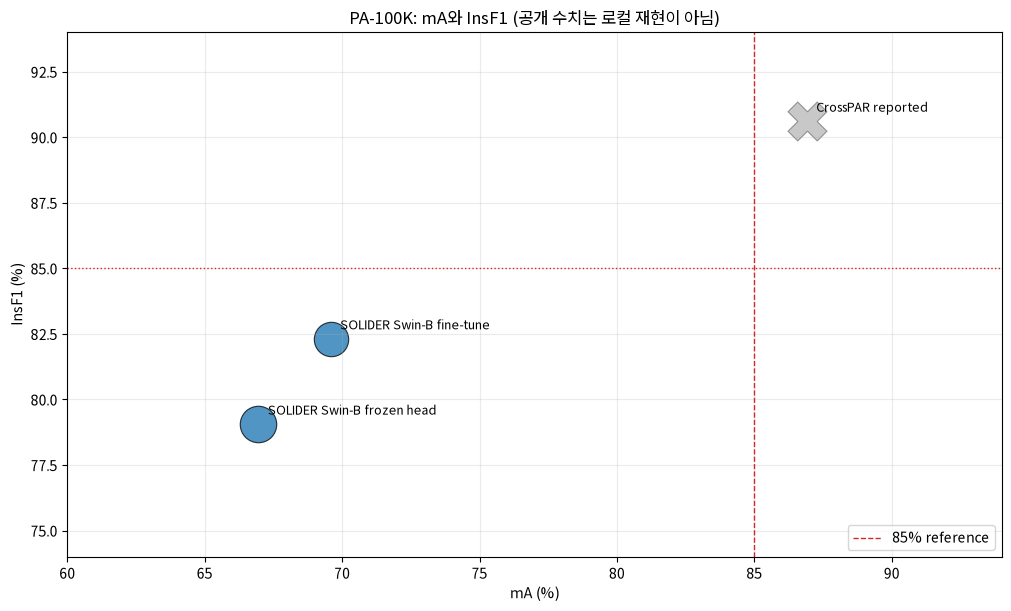

In [4]:
pa_rows = data['pa100kAttribute']
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
for row in pa_rows:
    is_public = row['status'] == 'reported_public'
    size = 250 + 110 * math.log10(row['bubble'])
    ax.scatter(row['x'], row['y'], s=size, alpha=0.78 if not is_public else 0.35, marker='X' if is_public else 'o', color='#636363' if is_public else '#1f78b4', edgecolor='black', linewidth=0.8)
    ax.annotate(row['label'], (row['x'], row['y']), xytext=(7, 7), textcoords='offset points', fontsize=9)
ax.axvline(85, color='#d62728', linestyle='--', linewidth=1, label='85% reference')
ax.axhline(85, color='#d62728', linestyle=':', linewidth=1)
ax.set_title('PA-100K: mA와 InsF1 (공개 수치는 로컬 재현이 아님)')
ax.set_xlabel('mA (%)')
ax.set_ylabel('InsF1 (%)')
ax.set_xlim(60, 94)
ax.set_ylim(74, 94)
ax.grid(alpha=0.25)
ax.legend(loc='lower right')
pa_png = project_root / 'experiments' / 'results' / 'model_comparison_pa100k_bubble.png'
pa_svg = project_root / 'experiments' / 'results' / 'model_comparison_pa100k_bubble.svg'
fig.savefig(pa_png, dpi=180)
fig.savefig(pa_svg)
plt.show()

### 3. 메인 차트와 직접 순위 비교하면 안 되는 보조 지표

These experiments are included for completeness, but their metric family and split differ from the two main charts. The y-axis is categorical by metric family, so compare points only within the same row.

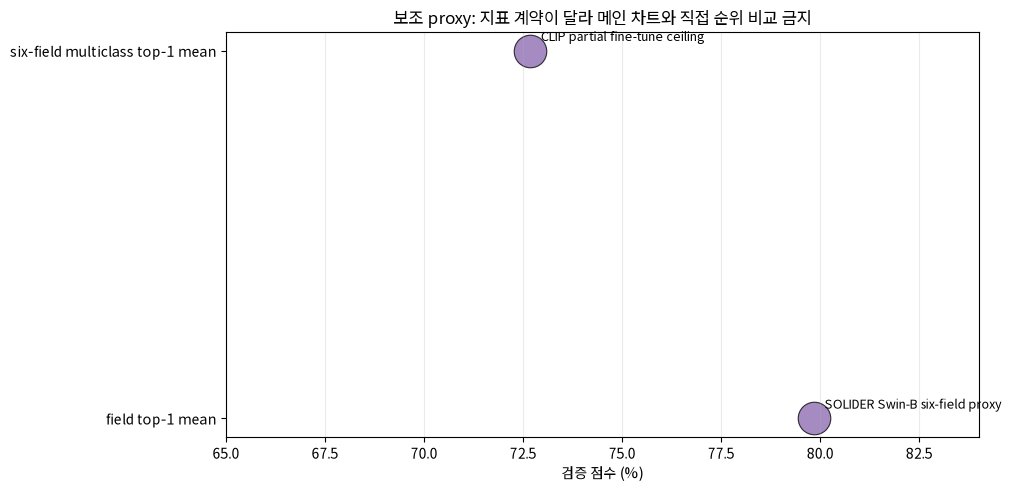

In [5]:
supplementary_rows = data['nonComparableMethods']
fig, ax = plt.subplots(figsize=(10, 4.8), constrained_layout=True)
for index, row in enumerate(supplementary_rows):
    ax.scatter(row['score_pct'], index, s=350 + 2 * row['examples'], alpha=0.78, color='#8c6bb1', edgecolor='black', linewidth=0.8)
    ax.annotate(row['label'], (row['score_pct'], index), xytext=(8, 7), textcoords='offset points', fontsize=9)
ax.set_yticks(range(len(supplementary_rows)))
ax.set_yticklabels([row['metric'] for row in supplementary_rows])
ax.set_xlabel('검증 점수 (%)')
ax.set_title('보조 proxy: 지표 계약이 달라 메인 차트와 직접 순위 비교 금지')
ax.set_xlim(65, 84)
ax.grid(alpha=0.25, axis='x')
supp_png = project_root / 'experiments' / 'results' / 'model_comparison_noncomparable_bubble.png'
supp_svg = project_root / 'experiments' / 'results' / 'model_comparison_noncomparable_bubble.svg'
fig.savefig(supp_png, dpi=180)
fig.savefig(supp_svg)
plt.show()

In [6]:
if qwen_measured:
    fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
    for row in qwen_measured:
        ax.scatter(row['x'], row['y'], s=250 + 180 * row['bubble'], alpha=0.78, color='#e66101' if '3.5' in row['label'] else '#5e3c99', edgecolor='black', linewidth=0.8)
        ax.annotate(row['label'], (row['x'], row['y']), xytext=(7, 7), textcoords='offset points', fontsize=9)
    ax.axvline(85, color='#d62728', linestyle='--', linewidth=1, label='85% 속성 정확도 기준선')
    ax.set_xlabel('6개 속성 정확도 (%)')
    ax.set_ylabel('6개 필드 완전일치 (%)')
    ax.set_title('동일 proxy split에서 Qwen base와 LoRA 비교')
    ax.grid(alpha=0.25)
    ax.legend()
    qwen_png = project_root / 'experiments' / 'results' / 'qwen_fair_finetuning_bubble.png'
    qwen_svg = project_root / 'experiments' / 'results' / 'qwen_fair_finetuning_bubble.svg'
    fig.savefig(qwen_png, dpi=180)
    fig.savefig(qwen_svg)
    plt.show()
else:
    print('Qwen 차트 보류: 유효한 base 또는 LoRA 결과 JSON이 없습니다')

Qwen 차트 보류: 유효한 base 또는 LoRA 결과 JSON이 없습니다


In [7]:
coordinate_path = project_root / 'experiments' / 'results' / 'model_comparison_bubble_coordinates.csv'
rows = []
for chart_name, chart_rows in [('proxyRuntime', data['proxyRuntime']), ('pa100kAttribute', data['pa100kAttribute'])]:
    for row in chart_rows:
        rows.append({'chart': chart_name, 'label': row['label'], 'x': row['x'], 'y': row['y'], 'bubble': row['bubble'], 'status': row['status'], 'metric': row.get('metric', ''), 'source': row['source']})
for index, row in enumerate(data['nonComparableMethods']):
    rows.append({'chart': 'nonComparableSupplement', 'label': row['label'], 'x': row['score_pct'], 'y': index, 'bubble': row['examples'], 'status': 'not_comparable', 'metric': row['metric'], 'source': row['source']})
measured_labels = {row['label'] for row in qwen_measured}
for row in data.get('qwenFairFineTuning', []):
    if row['label'] not in measured_labels:
        rows.append({'chart': 'qwenFairFineTuning', 'label': row['label'], 'x': row.get('x'), 'y': row.get('y'), 'bubble': row.get('bubble'), 'status': row['status'], 'metric': row.get('metric', ''), 'source': row['source']})
for row in qwen_measured:
    rows.append({'chart': 'qwenFairFineTuning', 'label': row['label'], 'x': row['x'], 'y': row['y'], 'bubble': row['bubble'], 'status': row['status'], 'metric': row['metric'], 'source': row['source']})
with coordinate_path.open('w', encoding='utf-8', newline='') as handle:
    writer = csv.DictWriter(handle, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)
print(f"wrote={coordinate_path} rows={len(rows)}")

wrote=C:\Users\SSAFY\Desktop\2학기\qwen3vl-backend\experiments\results\model_comparison_bubble_coordinates.csv rows=14


## 결론과 다음 단계

1. CLIP ViT-L/14가 proxy 속성 정확도 41.40%로 현재 1위지만 track exact가 0%라 단독 최종판단기로 승격할 수 없다.
2. BLIP base는 p95 0.492초로 가장 빠르지만 속성 정확도는 20.35%다. Qwen3-VL-2B는 39.30%로 2위지만 p95가 8.164초다.
3. SOLIDER Swin-B fine-tune은 현재 PA-100K subset 결과 중 가장 좋지만 mA 69.58%이며, 공개 CrossPAR 수치와도 평가 계약이 다르다.
4. Qwen3.5-9B와 Qwen2.5-VL-7B-Instruct는 아직 원격 인증·track-held-out 평가 전이므로 배포·fallback 승인을 보류한다. 다음 승격 기준은 실제 CCTV track split의 identity top-1, false-match rate, review rate, 속성 macro-F1이다.